# Previsão da frequência de acidentes de trânsito por características da via



## Problema

> É possível prever a quantidade anual de acidentes de um trecho viário a partir de suas características geométricas e operacionais?

A unidade de análise é **trecho-ano**: cada `ID` aparece em cinco anos. A resposta é `Acidentes`, uma contagem não negativa. O objetivo é apoiar triagem e priorização de estudos de segurança viária — não atribuir causalidade às características da via.

## Plano de análise

1. Importar o CSV e conferir qualidade e estrutura.
2. Explorar a distribuição e representar a frequência com um gráfico.
3. Treinar modelos de contagem em 2021–2024 e reservar 2025 para teste temporal.
4. Comparar uma referência simples, Poisson e binomial negativa.
5. Interpretar limites, exposição e próximos passos.

**Inspeção preliminar do arquivo fornecido:** 577 trechos em cinco anos (2.885 registros), cerca de 65% dos registros com zero acidente. A variância da contagem supera a média, então a binomial negativa é uma candidata importante. O notebook recalcula esses números após importar os dados.



## 1. Conectar ao Google Drive e carregar os dados

Coloque `BD_anos_empilhados_comprimento.csv` no Drive e ajuste `CAMINHO_CSV` para a localização correta. O CSV usa ponto e vírgula como separador.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")

# Ajuste o caminho conforme a pasta onde colocou o CSV.
CAMINHO_CSV = '/content/drive/MyDrive/BD_anos_empilhados_comprimento.csv'
assert Path(CAMINHO_CSV).exists(), f'Arquivo não encontrado: {CAMINHO_CSV}'

df = pd.read_csv(CAMINHO_CSV, sep=';', encoding='utf-8-sig')
df.columns = df.columns.str.strip()
for coluna in df.select_dtypes(include='object').columns:
    df[coluna] = df[coluna].str.strip()

print(f'{df.shape[0]:,} linhas × {df.shape[1]} colunas')
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
2,885 linhas × 20 colunas


,ID,Volume_P,Volume_S,Q_Faixa_P,Q_Faixa_S,L_Faixa_P,L_Faixa_S,Canterio_P,Canteiro_S,Est_P,Est_S,Inc_P,Inc_S,Controle,Moderacao,Veloc_P,Veloc_S,Ano,Acidentes,Comp_m
0,3,3,1,2,1,4.0,3.0,sim,nao,nao,nao,MB,B,sem_contr,sem_mod,50,40,2021,0.0,39.51
1,4,3,1,2,1,4.0,2.8,sim,nao,nao,sim,MB,B,pare,sem_mod,50,40,2021,0.0,39.51
2,5,3,2,4,1,3.0,4.0,sim,nao,sim,sim,B,B,sem_contr,sem_mod,50,40,2021,0.0,55.92
3,6,3,3,4,2,3.0,4.0,sim,sim,sim,nao,B,B,semaforo,radar,50,40,2021,1.0,53.69
4,7,3,3,4,2,3.0,4.0,sim,sim,sim,nao,M,B,semaforo,radar,50,40,2021,2.0,53.22


## 2. Entendimento dos dados


In [ ]:
print('Tipos de dados:')
display(df.dtypes.rename('tipo').to_frame())
print('Valores ausentes por coluna:')
display(df.isna().sum().sort_values(ascending=False).rename('ausentes').to_frame())
print('Anos:', sorted(df['Ano'].dropna().unique().tolist()))
print('Trechos únicos:', df['ID'].nunique())
print('Duplicatas ID-Ano:', df.duplicated(['ID', 'Ano']).sum())
print('Registros por ano:')
display(df.groupby('Ano').size().rename('registros').to_frame())
print('Resumo de Acidentes:')
display(df['Acidentes'].describe().to_frame())
print(f"Proporção de zeros: {df['Acidentes'].eq(0).mean():.1%}")
print(f"Variância / média: {df['Acidentes'].var() / df['Acidentes'].mean():.2f}")

# Verifique se as características se alteram para o mesmo trecho entre anos.
caracteristicas = [c for c in df.columns if c not in ['ID', 'Ano', 'Acidentes']]
variacao = df.groupby('ID')[caracteristicas].nunique(dropna=False)
variantes = variacao.columns[variacao.gt(1).any()].tolist()
print('Características que variam dentro do ID:', variantes or 'nenhuma')

Tipos de dados:


,tipo
ID,int64
Volume_P,int64
Volume_S,int64
Q_Faixa_P,int64
Q_Faixa_S,int64
L_Faixa_P,float64
L_Faixa_S,float64
Canterio_P,object
Canteiro_S,object
Est_P,object


Valores ausentes por coluna:


,ausentes
ID,0
Volume_P,0
Volume_S,0
Q_Faixa_P,0
Q_Faixa_S,0
L_Faixa_P,0
L_Faixa_S,0
Canterio_P,0
Canteiro_S,0
Est_P,0


Anos: [2021, 2022, 2023, 2024, 2025]
Trechos únicos: 577
Duplicatas ID-Ano: 0
Registros por ano:


,registros
Ano,
2021,577
2022,577
2023,577
2024,577
2025,577


Resumo de Acidentes:


,Acidentes
count,2885.000000
mean,0.599653
std,1.055104
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,9.000000


Proporção de zeros: 64.8%
Variância / média: 1.86
Características que variam dentro do ID: nenhuma


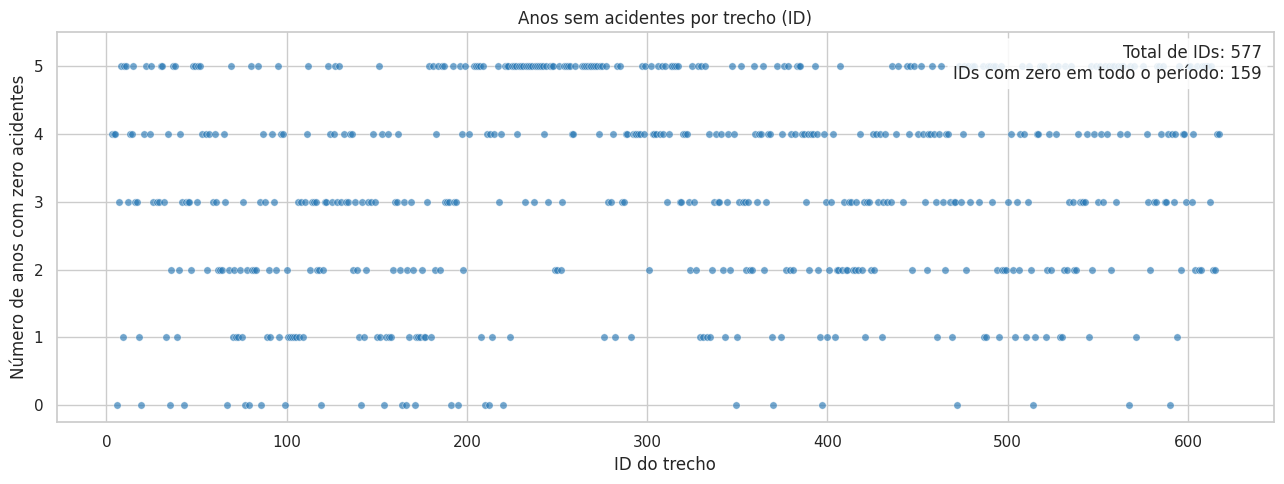

,ID,anos_com_zero,anos_observados,acidentes_total
0,3,4,5,1.0
1,4,4,5,1.0
2,5,4,5,2.0
3,6,0,5,9.0
4,7,3,5,5.0


In [ ]:
# Gráfico: ID do trecho × número de anos com zero acidentes
# Um ponto representa um ID; o eixo Y conta em quantos anos Acidentes == 0.
zero_por_id = (
    df.assign(ano_zero=df['Acidentes'].eq(0).astype(int))
      .groupby('ID', as_index=False)
      .agg(anos_com_zero=('ano_zero', 'sum'),
           anos_observados=('Ano', 'nunique'),
           acidentes_total=('Acidentes', 'sum'))
      .sort_values('ID')
)

fig, ax = plt.subplots(figsize=(13, 5))
ax.scatter(zero_por_id['ID'], zero_por_id['anos_com_zero'],
           alpha=0.65, s=28, color='#2878B5', edgecolor='white', linewidth=.4)
ax.set(title='Anos sem acidentes por trecho (ID)',
       xlabel='ID do trecho', ylabel='Número de anos com zero acidentes')
ax.set_yticks(range(int(zero_por_id['anos_com_zero'].max()) + 1))
ax.set_ylim(-0.25, zero_por_id['anos_com_zero'].max() + 0.5)
ax.text(0.99, 0.97,
        f"Total de IDs: {zero_por_id['ID'].nunique()}\n"
        f"IDs com zero em todo o período: {(zero_por_id['acidentes_total'] == 0).sum()}",
        transform=ax.transAxes, ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=.85))
plt.tight_layout()
plt.show()

display(zero_por_id.head())

In [ ]:
# Separar o DataFrame em um dicionário: uma tabela para cada ano
dados_por_ano = {
    int(ano): grupo.copy()
    for ano, grupo in df.groupby('Ano', sort=True)
}

print('Quantidade de registros em cada tabela:')
for ano, tabela in dados_por_ano.items():
    print(f'{ano}: {len(tabela)} registros | {tabela["ID"].nunique()} IDs')

# Exemplos de acesso:
df_2021 = dados_por_ano.get(2021)
df_2025 = dados_por_ano.get(2025)
#display(df_2021.head())

Quantidade de registros em cada tabela:
2021: 577 registros | 577 IDs
2022: 577 registros | 577 IDs
2023: 577 registros | 577 IDs
2024: 577 registros | 577 IDs
2025: 577 registros | 577 IDs


## 3. Visualização principal

Para cada ano, o eixo horizontal mostra a quantidade de acidentes, e o tamanho da bolha mostra quantos registros trecho-ano tiveram essa contagem. Os números dentro das bolhas facilitam a leitura da distribuição de zeros e da cauda de contagens altas.

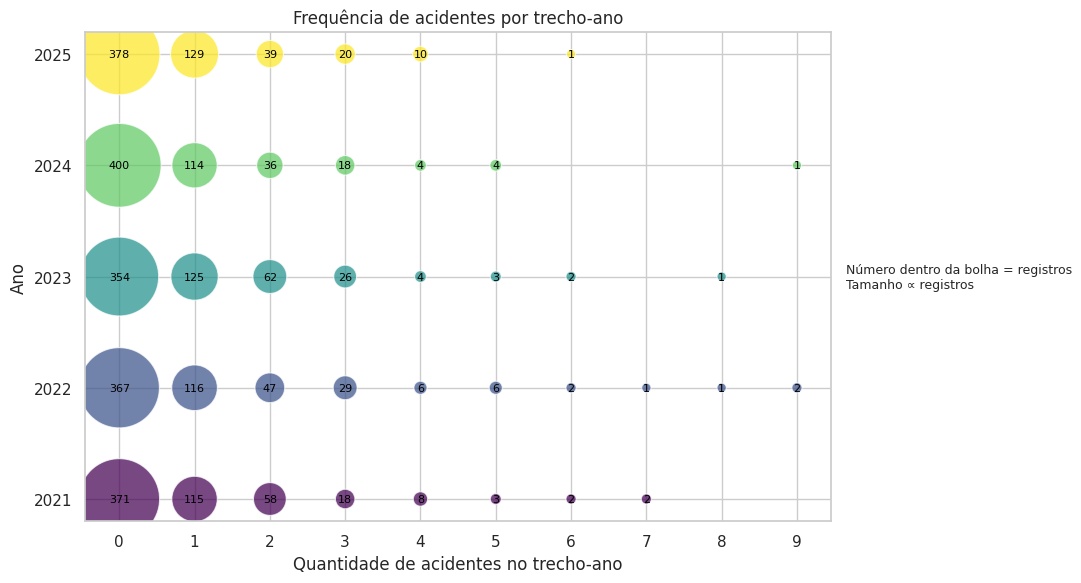

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')

freq = df.groupby(['Ano', 'Acidentes']).size().reset_index(name='n_trechos_ano')
fig, ax = plt.subplots(figsize=(11, 6))
tamanhos = 35 + 9 * freq['n_trechos_ano']
ax.scatter(freq['Acidentes'], freq['Ano'], s=tamanhos, c=freq['Ano'],
           cmap='viridis', alpha=.72, edgecolor='white', linewidth=.8)
for _, r in freq.iterrows():
    ax.annotate(str(int(r['n_trechos_ano'])), (r['Acidentes'], r['Ano']),
                ha='center', va='center', fontsize=8, color='black')
ax.set(title='Frequência de acidentes por trecho-ano',
       xlabel='Quantidade de acidentes no trecho-ano', ylabel='Ano')
ax.set_yticks(sorted(df['Ano'].unique()))
ax.set_xticks(range(int(df['Acidentes'].min()), int(df['Acidentes'].max()) + 1))
ax.text(1.02, .5, 'Número dentro da bolha = registros\nTamanho ∝ registros',
        transform=ax.transAxes, va='center', fontsize=9)
plt.tight_layout()
plt.show()

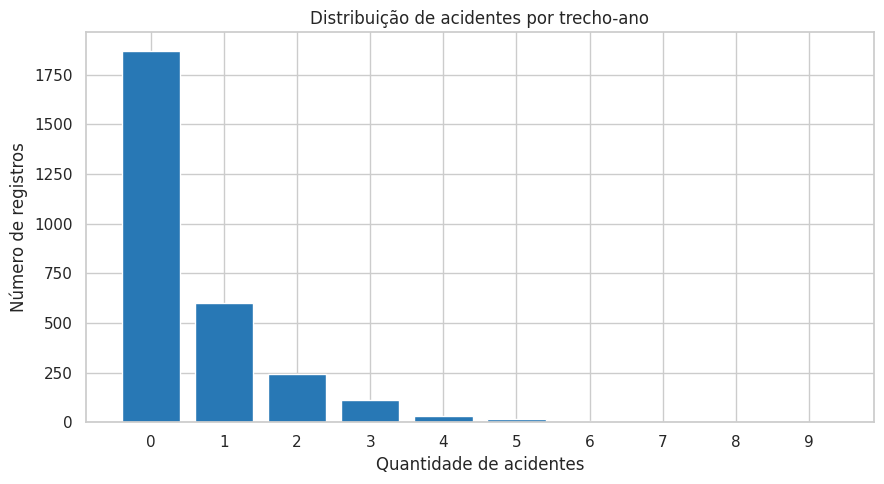

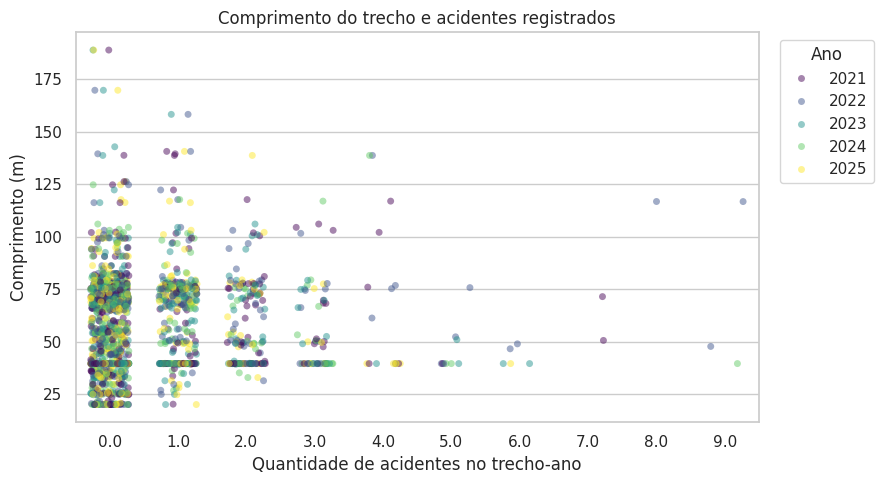

In [ ]:
# Distribuição agregada da resposta
contagem = df['Acidentes'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(contagem.index.astype(int), contagem.values, color='#2878B5')
ax.set(title='Distribuição de acidentes por trecho-ano',
       xlabel='Quantidade de acidentes', ylabel='Número de registros')
ax.set_xticks(contagem.index.astype(int))
plt.tight_layout()
plt.show()

# Relação exploratória entre comprimento e contagem (não causal).
amostra = df.sample(min(len(df), 1800), random_state=42)
fig, ax = plt.subplots(figsize=(9, 5))
sns.stripplot(data=amostra, x='Acidentes', y='Comp_m', hue='Ano',
              jitter=.28, alpha=.48, dodge=False, ax=ax, palette='viridis')
ax.set(title='Comprimento do trecho e acidentes registrados',
       xlabel='Quantidade de acidentes no trecho-ano', ylabel='Comprimento (m)')
ax.legend(title='Ano', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 4. Estratégia de modelagem

A resposta é uma **contagem**, então regressão linear comum não é a primeira escolha. Poisson é uma referência natural; com sobredispersão, a **binomial negativa** é uma alternativa flexível.


### Validação

O teste abaixo usa 2025 como ano futuro, treinando em 2021–2024. O ano entra como tendência numérica (`Ano_c`), e não como categoria: assim o modelo pode prever um ano que não apareceu no treino.

### Codificação

O exemplo trata `Volume_*`, `Q_Faixa_*` e campos textuais como categóricos. Valores codificados como classes devem ser categorias; medidas reais podem ser contínuas. `ID` não entra como preditor.

In [72]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance

assert {'Acidentes', 'Ano', 'ID', 'Comp_m'}.issubset(df.columns)
assert (df['Acidentes'] >= 0).all(), 'Acidentes deve ser não negativo.'
assert (df['Comp_m'] > 0).all(), 'Comp_m precisa ser positivo para o offset.'

categoricas = [
    'Volume_P', 'Volume_S', 'Q_Faixa_P', 'Q_Faixa_S', 'Canterio_P',
    'Canteiro_S', 'Est_P', 'Est_S', 'Inc_P', 'Inc_S', 'Controle', 'Moderacao'
]
categoricas = [c for c in categoricas if c in df.columns]
for c in categoricas:
    df[c] = df[c].astype('category')
continuas = [c for c in ['L_Faixa_P', 'L_Faixa_S', 'Veloc_P', 'Veloc_S'] if c in df.columns]

# Aproximação da exposição em quilômetros-trecho por ano.
df['exposicao_km'] = df['Comp_m'] / 1000
df['Ano_c'] = df['Ano'] - df['Ano'].min()
treino = df[df['Ano'] < 2025].copy()
teste = df[df['Ano'] == 2025].copy()
assert len(treino) and len(teste), 'Confira se há anos anteriores a 2025 e ano 2025.'
print(f'Treino: {len(treino):,} linhas | Teste 2025: {len(teste):,} linhas')
print(f"IDs: {treino.ID.nunique()} no treino; {teste.ID.nunique()} no teste")

termos = [f'C({c})' for c in categoricas] + continuas + ['Ano_c']
formula = 'Acidentes ~ ' + ' + '.join(termos)
print('Fórmula:', formula)

Treino: 2,308 linhas | Teste 2025: 577 linhas
IDs: 577 no treino; 577 no teste
Fórmula: Acidentes ~ C(Volume_P) + C(Volume_S) + C(Q_Faixa_P) + C(Q_Faixa_S) + C(Canterio_P) + C(Canteiro_S) + C(Est_P) + C(Est_S) + C(Inc_P) + C(Inc_S) + C(Controle) + C(Moderacao) + L_Faixa_P + L_Faixa_S + Veloc_P + Veloc_S + Ano_c


## 5. Ajustar e comparar modelos

Comparamos uma referência pela taxa média por m, Poisson com regularização L2 e binomial negativa. A regularização estabiliza o Poisson quando há categorias raras/separação; o valor de `alpha` é apenas um ponto de partida e deve ser escolhido por validação interna no período de treino. A binomial negativa estima a dispersão nos dados de treino. Se houver problemas de convergência, simplifique a fórmula de modo documentado e confira a codificação.

In [73]:
offset_treino = np.log(treino['exposicao_km'])
offset_teste = np.log(teste['exposicao_km'])

# Baseline: acidentes médios por km no conjunto de treino.
taxa = treino['Acidentes'].sum() / treino['exposicao_km'].sum()
pred_baseline = taxa * teste['exposicao_km']

# L2 leve para estabilizar a estimação com níveis raros nas variáveis categóricas.
modelo_poisson = smf.glm(
    formula, data=treino, family=sm.families.Poisson(), offset=offset_treino
).fit_regularized(alpha=0.01, L1_wt=0.0, maxiter=500)
pred_poisson = modelo_poisson.predict(teste, offset=offset_teste)

modelo_nb = smf.negativebinomial(
    formula, data=treino, offset=offset_treino
).fit(disp=False, maxiter=200)
pred_nb = modelo_nb.predict(teste, offset=offset_teste)
print(modelo_nb.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(


                     NegativeBinomial Regression Results                      
Dep. Variable:              Acidentes   No. Observations:                 2308
Model:               NegativeBinomial   Df Residuals:                     2278
Method:                           MLE   Df Model:                           29
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.1064
Time:                        01:09:51   Log-Likelihood:                -2217.6
converged:                       True   LL-Null:                       -2481.6
Covariance Type:            nonrobust   LLR p-value:                 4.914e-93
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                    1.3278        nan        nan        nan         nan         nan
C(Volume_P)[T.2]             1.1494        nan        nan        nan         nan         

### Consultar as previsões por trecho para 2025

Depois de ajustar os modelos, esta célula mostra a previsão de cada ID e permite comparar a soma prevista com os acidentes observados em 2025.


In [74]:
modelo1 = 'prev_modelo1'
modelo2 = 'prev_modelo2'
modelo3 = 'prev_modelo3'

# Tabela completa de valores reais e previstos no teste temporal de 2025.
previsoes_2025 = teste[['ID', 'Ano', 'Acidentes']].copy()
previsoes_2025 = previsoes_2025.rename(columns={'Acidentes': 'acidentes_observados'})

previsoes_2025[modelo1] = np.asarray(pred_baseline)
previsoes_2025[modelo2] = np.asarray(pred_poisson)
previsoes_2025[modelo3] = np.asarray(pred_nb)




# =========================
# Adicionar linha em branco + linha de TOTAL
# =========================

# 1. Linha em branco
linha_em_branco = pd.Series(
    [np.nan] * len(previsoes_2025.columns),
    index=previsoes_2025.columns
)

# 2. Linha de total
linha_total = pd.Series({
    'ID': 'TOTAL',
    'Ano': np.nan,
    'acidentes_observados': previsoes_2025['acidentes_observados'].sum(),
    modelo1: previsoes_2025[modelo1].sum(),
    modelo2: previsoes_2025[modelo2].sum(),
    modelo3: previsoes_2025[modelo3].sum(),

})

# 3. Concatenar tudo
previsoes_2025_final = pd.concat(
    [previsoes_2025,
     pd.DataFrame([linha_em_branco]),
     pd.DataFrame([linha_total])],
    ignore_index=True
)

# Visualizar
#display(previsoes_2025_final.sort_values('ID', na_position='last').round(3))

print(f"Total observado em 2025: {previsoes_2025['acidentes_observados'].sum():.0f}")
print(f"Total previsto pelo Baseline (modelo1): {previsoes_2025[modelo1].sum():.1f}")
print(f"Total previsto pelo Poisson (modelo2): {previsoes_2025[modelo2].sum():.1f}")
print(f"Total previsto pela Binomial Negativa (modelo3): {previsoes_2025[modelo3].sum():.1f}")

# Salvar a tabela completa (com linha em branco + total)
CAMINHO_PREVISOES = '/content/drive/MyDrive/previsoes_acidentes_2025.csv'
previsoes_2025_final.to_csv(CAMINHO_PREVISOES, index=False, encoding='utf-8-sig')
print(f'Tabela completa salva em: {CAMINHO_PREVISOES}')

Total observado em 2025: 313
Total previsto pelo Baseline (modelo1): 354.2
Total previsto pelo Poisson (modelo2): 301.0
Total previsto pela Binomial Negativa (modelo3): 307.8
Tabela completa salva em: /content/drive/MyDrive/previsoes_acidentes_2025.csv


## 6. Avaliação no ano de teste

Calculamos MAE, RMSE e R² para comparar valores observados e previstos em 2025; também mantemos o desvio de Poisson como diagnóstico complementar para contagens. MAE/RMSE menores e R² maior são, em geral, preferíveis, mas R² pode ser negativo. O CURE Plot acumula resíduos ao longo de uma variável ordenada; bandas apresentadas são aproximações sob independência e variância binomial negativa, e devem ser interpretadas com cautela por haver medidas repetidas por trecho ao longo do painel.


MAE e RMSE: menores são melhores. R²: maior é melhor; pode ser negativo.


,MAE,RMSE,R²,Desvio de Poisson
Baseline taxa por km,0.721,0.957,-0.076,1.387
Poisson,0.594,0.836,0.178,1.060
Binomial negativa,0.586,0.842,0.168,1.069


,previsao_media,acidentes_observados,n
0,0.070,0.155,58
1,0.121,0.138,58
2,0.181,0.298,57
3,0.303,0.241,58
4,0.406,0.424,59
5,0.494,0.375,56
6,0.623,0.552,58
7,0.720,0.702,57
8,0.897,1.086,58
9,1.517,1.448,58


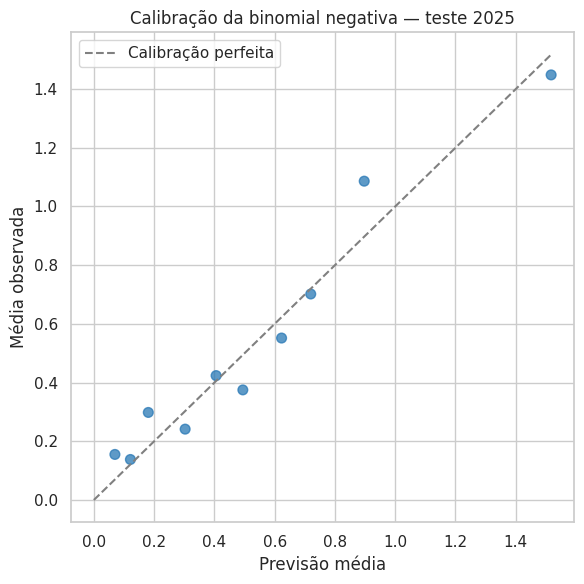

In [75]:
from sklearn.metrics import r2_score

def metricas(y, pred):
    pred = np.clip(np.asarray(pred, dtype=float), 1e-9, None)
    return {
        'MAE': mean_absolute_error(y, pred),
        'RMSE': mean_squared_error(y, pred) ** .5,
        'R²': r2_score(y, pred),
        'Desvio de Poisson': mean_poisson_deviance(y, pred),
    }

resultados = pd.DataFrame({
    'Baseline taxa por km': metricas(teste['Acidentes'], pred_baseline),
    'Poisson': metricas(teste['Acidentes'], pred_poisson),
    'Binomial negativa': metricas(teste['Acidentes'], pred_nb),
}).T
print('MAE e RMSE: menores são melhores. R²: maior é melhor; pode ser negativo.')
display(resultados.round(3))

# Calibração agregada da binomial negativa por decis de previsão.
cal = pd.DataFrame({'observado': teste['Acidentes'].to_numpy(), 'previsto': np.asarray(pred_nb)})
cal['grupo'] = pd.qcut(cal['previsto'], q=10, duplicates='drop')
cal = cal.groupby('grupo', observed=True).agg(
    previsao_media=('previsto', 'mean'),
    acidentes_observados=('observado', 'mean'),
    n=('observado', 'size')
).reset_index(drop=True)
display(cal.round(3))
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(cal['previsao_media'], cal['acidentes_observados'],
           s=30 + cal['n']/3, alpha=.75, color='#2878B5')
lim = max(cal['previsao_media'].max(), cal['acidentes_observados'].max())
ax.plot([0, lim], [0, lim], '--', color='gray', label='Calibração perfeita')
ax.set(xlabel='Previsão média', ylabel='Média observada',
       title='Calibração da binomial negativa — teste 2025')
ax.legend()
plt.tight_layout()
plt.show()

### CURE Plot — resíduos acumulados

O gráfico abaixo ordena os trechos por uma variável explicativa contínua (padrão: comprimento) e acumula `observado − previsto`. Uma tendência sistemática dos resíduos pode indicar falta de ajuste. As bandas de 95% são aproximações baseadas na variância NB2 e assumem independência entre observações; para inferência mais rigorosa, use simulação/bootstrapping que respeite agrupamento por ID e dependência espacial.


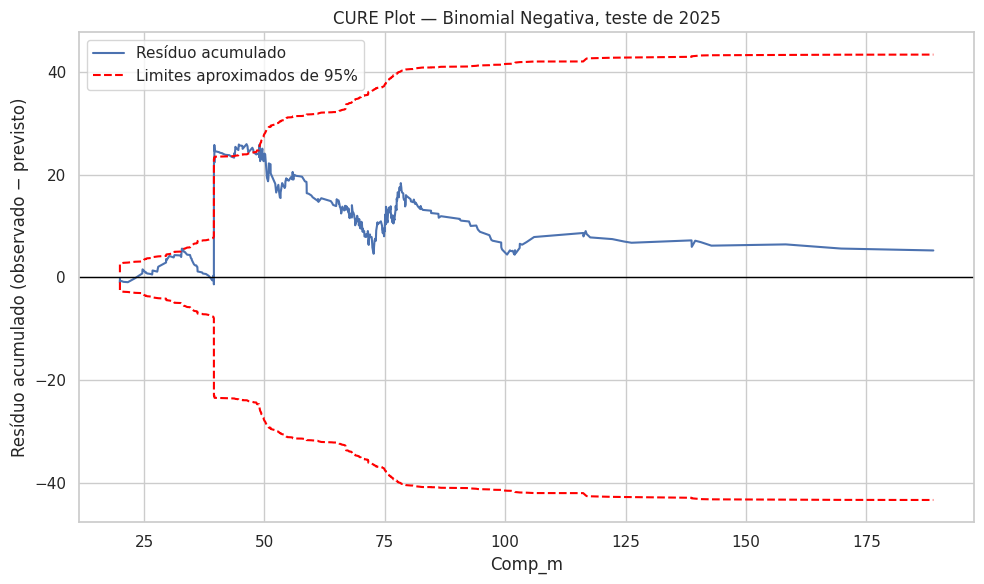

In [77]:
import numpy as np
import matplotlib.pyplot as plt

VARIAVEL_CURE = 'Comp_m'

# modelo3 contém o nome da coluna da previsão da Binomial Negativa
# definido anteriormente como: modelo3 = 'prev_modelo3'
assert modelo3 in previsoes_2025.columns, f'Coluna não encontrada: {modelo3}'

# Montar a tabela de teste e juntar as previsões pelo ID
cure = teste[['ID', VARIAVEL_CURE, 'Acidentes']].copy()
cure = cure.rename(columns={'Acidentes': 'observado'})

cure = cure.merge(
    previsoes_2025[['ID', modelo3]],
    on='ID',
    how='inner',
    validate='one_to_one'
).rename(columns={modelo3: 'previsto'})

# Ordenar pela variável escolhida e acumular os resíduos
cure = cure.sort_values(VARIAVEL_CURE).reset_index(drop=True)
cure['residuo'] = cure['observado'] - cure['previsto']
cure['residuo_acumulado'] = cure['residuo'].cumsum()

# Bandas aproximadas para NB2: Var(Y|X) = mu + alpha * mu²
alpha_nb = float(modelo_nb.params['alpha'])
mu = cure['previsto'].to_numpy()
variancia = mu + alpha_nb * mu**2
banda_95 = 1.96 * np.sqrt(np.cumsum(variancia))

# Desenhar o CURE Plot
x = cure[VARIAVEL_CURE].to_numpy()

plt.figure(figsize=(10, 6))
plt.plot(x, cure['residuo_acumulado'], label='Resíduo acumulado')
plt.plot(x, banda_95, '--', color='red', label='Limites aproximados de 95%')
plt.plot(x, -banda_95, '--', color='red')
plt.axhline(0, color='black', linewidth=1)

plt.xlabel(VARIAVEL_CURE)
plt.ylabel('Resíduo acumulado (observado − previsto)')
plt.title('CURE Plot — Binomial Negativa, teste de 2025')
plt.legend()
plt.tight_layout()
plt.show()


## 7. Interpretar resultados e comunicar

Em modelos log-lineares, os coeficientes estão na escala logarítmica. `exp(coeficiente)` é uma razão de taxas: por exemplo, 1,10 significa taxa esperada 10% maior, condicionada aos demais termos e às categorias de referência. É associação, não causalidade. Considere plausibilidade de engenharia, intervalos de confiança e estabilidade entre anos.

Como registros do mesmo `ID` são correlacionados, inferência estatística deve considerar o agrupamento por trecho (por exemplo, erros-padrão agrupados, GEE ou modelo misto). A validação temporal avalia o cenário de próximo ano em trechos existentes; ela não prova generalização para vias novas.

In [78]:
# Razões de taxas e intervalos de confiança para uma leitura inicial.
coef = modelo_nb.params
ic = modelo_nb.conf_int()
resumo_coef = pd.DataFrame({
    'coef_log': coef,
    'razao_de_taxas': np.exp(coef),
    'IC95_inf_razao': np.exp(ic[0]),
    'IC95_sup_razao': np.exp(ic[1]),
})
display(resumo_coef.round(3))

,coef_log,razao_de_taxas,IC95_inf_razao,IC95_sup_razao
Intercept,1.328,3.773000e+00,NaN,NaN
C(Volume_P)[T.2],1.149,3.156000e+00,NaN,NaN
C(Volume_P)[T.3],1.620,5.054000e+00,NaN,NaN
C(Volume_S)[T.1],-0.255,7.750000e-01,NaN,NaN
C(Volume_S)[T.2],0.046,1.047000e+00,NaN,NaN
C(Volume_S)[T.3],0.200,1.222000e+00,NaN,NaN
C(Q_Faixa_P)[T.2],0.020,1.020000e+00,NaN,NaN
C(Q_Faixa_P)[T.3],1.148,3.152000e+00,NaN,NaN
C(Q_Faixa_P)[T.4],0.468,1.597000e+00,NaN,NaN
C(Q_Faixa_S)[T.1],17.686,4.797525e+07,NaN,NaN
